# §5 Labels and Bias Audit (Stage S5)

A diabetes label is itself a measurement. Self-report records a past diagnosis and HbA1c records today's
glycaemia under whatever treatment the person receives; neither is "the truth". This section audits the label
layer and two further bias layers before the target is frozen (freeze point 2, `target-freeze`):

| Step | Question | Output |
|---|---|---|
| 1 | How far do self-report and HbA1c agree? | confusion table, κ, PA/NA (`label_audit.csv`) |
| 2 | Does treatment hide diabetes from HbA1c? | treatment masking, A1c-by-medication figure |
| 3 | What does "undiagnosed" mean? | care contact of the undiagnosed |
| 4 | Who is undiagnosed? | risk differences, Korn–Graubard CIs, NCHS flags (`undiagnosed_by_group.csv`) |
| 5 | Does BMI measure adiposity equally for Asian adults? | BMI vs WHtR AUC by race (`bmi_race_roc.csv`) |
| 6 | Whom do the 5,730 represent? | sample vs weighted shares, response, exam selection (`representation.csv`) |
| 7 | Is HbA1c missing at random? | missingness by race, Manski bounds |
| 8 | Decision gate L2 and freeze | C1–C4, `L_comb`, E-SCREEN, 3×3 strata, SL1–SL7 (`governance/label_freeze.md`) |

All findings here were obtained after looking at the data (`prior_exposure = analysis_seen`); they motivate,
but do not count as, pre-registered tests.

In [1]:
import sys, pathlib
_here = pathlib.Path.cwd()
ROOT = next(p for p in [_here, *_here.parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
from src import config as C, plots, results_io as R

import hashlib
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.metrics import roc_auc_score

from src import evalkit as E, labels as L, nhanes_io as NIO, survey as S

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
OUT = C.RESULTS_DIR / "S5"
OUT.mkdir(parents=True, exist_ok=True)
WT = C.WEIGHT_PHLEB                      # WTPH2YR: cohort analyses (HbA1c sample)
REG_DATE = "2026-10-11"
RACE = {1: "Mexican American", 2: "Other Hispanic", 3: "NH White", 4: "NH Black", 6: "NH Asian", 7: "Other/multi"}
RES: dict = {}                           # -> results/metrics_S5.json
REG: list[dict] = []                     # -> governance/register/S5.csv


def close(value, target, tol, what):
    """Assert a recomputed number against the verified value of process doc §8 / S5 plan."""
    assert abs(value - target) <= tol, f"{what}: got {value:.4f}, expected {target} ± {tol}"


def register(dr_id, type_, finding, evidence_ref, evidence_value, decision, alternatives_rejected,
             *, hyp_id="", status="decided", check_verdict="PASS", check_note="", loop_ref=""):
    REG.append(dict(dr_id=dr_id, stage="S5", date=REG_DATE, type=type_, finding=finding,
                    evidence_ref=evidence_ref, evidence_value=evidence_value, decision=decision,
                    alternatives_rejected=alternatives_rejected, hyp_id=hyp_id, status=status,
                    check_verdict=check_verdict, check_note=check_note, loop_ref=loop_ref,
                    change_request="", commit=""))


def pct(x, nd=1):
    return f"{100 * x:.{nd}f}%"


def kg_text(r):
    flag = "exploratory, does not meet NCHS standard" if r["nchs_flags"] else "meets NCHS standard"
    return (f"{pct(r['est'])} (KG {pct(r['kg_low'])}–{pct(r['kg_high'])}, width {r['ci_width']:.2f}; "
            f"n={r['n']}, events={r['n_events']}, df={r['df']}) -> {flag}")


cohort = NIO.build_cohort()
cohort.attrs = {}   # drop the attached sentinel-audit DataFrame (pandas cannot compare DataFrame attrs in concat)
d = L.add_labels(cohort)
assert len(d) == NIO.COHORT_N == 5730
d["race3"] = d["RIDRETH3"].map(RACE)
print(f"cohort: {len(d):,} adults; columns: {d.shape[1]}")

cohort: 5,730 adults; columns: 81


## 1 Three labels and their agreement

**Why.** The research question needs a diabetes label, and the data offer two independent instruments:
`L_self` (DIQ010 = 1, "a doctor told you that you have diabetes") and `L_A1c` (HbA1c ≥ 6.5 %, measured at the
exam). `L_comb` is their union. Before choosing one, we measure how much they agree. Cohen's κ is reported
unweighted and weighted (WTPH2YR, delete-one-PSU jackknife, df = 15). Because κ depends on prevalence, the
positive and negative specific agreements (PA, NA) are reported alongside, as well as the sensitivity and PPV
of self-report against HbA1c.

In [2]:
tab = L.confusion(d)
print("Self-report (rows) x HbA1c >= 6.5 (columns), unweighted counts")
print(tab, "\n")
unw = L.agreement(d)
jk_agree = S.jackknife(d, L.agreement_vector, weight=WT)
agree = pd.DataFrame({
    "unweighted": [unw[k] for k in L.AGREEMENT_KEYS],
    "weighted": jk_agree["est"], "w_ci_low": jk_agree["ci_low"], "w_ci_high": jk_agree["ci_high"],
}, index=list(L.AGREEMENT_KEYS)).round(3)
print(agree)

L.check_frozen_counts(d)
close(unw["kappa"], 0.699, 0.0015, "kappa unweighted")
close(unw["pa"], 0.739, 0.0015, "PA")
close(unw["na"], 0.959, 0.0015, "NA")
close(unw["sens"], 0.789, 0.0015, "sensitivity of self-report")
close(unw["ppv"], 0.695, 0.0015, "PPV of self-report")
close(jk_agree["est"][0], 0.709, 0.0015, "kappa weighted")
close(jk_agree["ci_low"][0], 0.665, 0.002, "kappa weighted CI low")
close(jk_agree["ci_high"][0], 0.752, 0.002, "kappa weighted CI high")

n_comb = int(d["L_comb"].sum())
miss_self, miss_a1c = int(tab.loc[0, 1]), int(tab.loc[1, 0])
w_prev = S.weighted_prop(d, "L_comb", weight=WT)
print(f"\nL_comb positives {n_comb} ({pct(n_comb / len(d))} unweighted; weighted {kg_text(w_prev)})")
print(f"L_self misses {miss_self}/{n_comb} = {pct(miss_self / n_comb)} of L_comb positives; "
      f"L_A1c misses {miss_a1c}/{n_comb} = {pct(miss_a1c / n_comb)}")
close(w_prev["est"], 0.140, 0.0015, "weighted L_comb prevalence")

label_audit = pd.DataFrame([
    {"label": lab, "positives": int(d[lab].sum()), "prev_unweighted": d[lab].mean(),
     **{f"w_{k}": v for k, v in S.weighted_prop(d, lab, weight=WT).items()
        if k in ("est", "kg_low", "kg_high", "df")}}
    for lab in L.LABEL_COLS])
label_audit.to_csv(OUT / "label_audit.csv", index=False)
agree.to_csv(OUT / "label_agreement.csv")
RES["labels"] = {
    "confusion": {f"self{i}_a1c{j}": int(tab.loc[i, j]) for i in (0, 1) for j in (0, 1)},
    "agreement_unweighted": {k: unw[k] for k in L.AGREEMENT_KEYS},
    "agreement_weighted": {k: {"est": e, "ci_low": lo, "ci_high": hi} for k, e, lo, hi in
                           zip(L.AGREEMENT_KEYS, jk_agree["est"], jk_agree["ci_low"], jk_agree["ci_high"])},
    "positives": {lab: int(d[lab].sum()) for lab in L.LABEL_COLS},
    "L_comb_weighted": {k: w_prev[k] for k in ("est", "ci_low", "ci_high", "kg_low", "kg_high")},
    "L_comb_unweighted": n_comb / len(d),
    "self_missed_share": miss_self / n_comb, "a1c_missed_share": miss_a1c / n_comb,
}
register("DR-S5-02", "label_audit",
         "Self-report and HbA1c are two different instruments with moderate-to-substantial agreement",
         "results/S5/label_agreement.csv; §5.1",
         f"kappa {unw['kappa']:.3f} (weighted {jk_agree['est'][0]:.3f}, CI {jk_agree['ci_low'][0]:.3f}-"
         f"{jk_agree['ci_high'][0]:.3f}); PA {unw['pa']:.3f}; NA {unw['na']:.3f}; sens {unw['sens']:.3f}; PPV {unw['ppv']:.3f}",
         "Use the union L_comb as training target; report PA/NA next to kappa; keep L_self and L_A1c as sensitivity labels SL2/SL1",
         "Single-instrument label (L_self or L_A1c) as target; kappa alone (prevalence-dependent)",
         check_note="Confusion table, kappa, PA/NA, sens/PPV recomputed and asserted against process doc §8")

Self-report (rows) x HbA1c >= 6.5 (columns), unweighted counts
L_A1c      0    1
L_self           
0       4759  152
1        250  569 

       unweighted  weighted  w_ci_low  w_ci_high
kappa       0.699     0.709     0.665      0.752
pa          0.739     0.741     0.701      0.781
na          0.959     0.968     0.962      0.973
sens        0.789     0.784     0.738      0.830
ppv         0.695     0.703     0.652      0.753

L_comb positives 971 (16.9% unweighted; weighted 14.0% (KG 12.5%–15.7%, width 0.03; n=5730, events=971, df=15) -> meets NCHS standard)
L_self misses 152/971 = 15.7% of L_comb positives; L_A1c misses 250/971 = 25.7%


**So what.** The two instruments agree on 93 % of adults, but agreement *on cases* is much weaker: κ = 0.699
(weighted 0.709, CI 0.665–0.752, "substantial" on the Landis–Koch scale only just), PA = 0.739 against
NA = 0.959. Self-report detects 78.9 % of HbA1c-positive adults, and only 69.5 % of self-reported diabetics
are HbA1c-positive on the day of the exam. Each single instrument misses a large part of the union:
`L_self` misses 152/971 = 15.7 % of `L_comb` positives and `L_A1c` misses 250/971 = 25.7 %. The disagreement
is structured, not random noise; steps 2–3 show why.

## 2 Treatment masking

**Why.** 250 self-reported diabetics have HbA1c < 6.5 %. If most of them are treated, a low HbA1c is the
*result* of diagnosis and treatment, and an HbA1c-only label would call well-controlled patients "healthy".
Medication (insulin DIQ050, pills DIQ070) is post-diagnosis information, so it is used here for the audit only,
never as a feature.

self-reported diabetics: 819; HbA1c < 6.5: 250 (30.5%)
  of these on insulin or pills: 165 (66%); untreated: 85, of whom 50 have HbA1c 5.7-6.4
treated self-reported diabetics: 694; HbA1c < 6.5 among them: 23.8%

HbA1c (%) of self-reported diabetics by treatment
                  count  mean   std  min  25%  50%  75%   max
on_med                                                       
insulin or pills  694.0  7.64  1.75  4.1  6.5  7.2  8.3  17.1
no medication     125.0  6.53  1.72  4.7  5.6  6.1  6.7  15.6


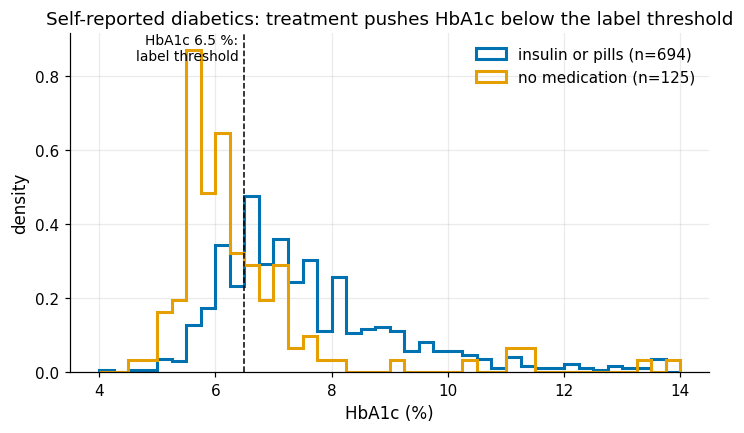

In [3]:
sr = d[d["L_self"] == 1]
ctrl = sr[sr["L_A1c"] == 0]
n_ctrl, n_ctrl_med = len(ctrl), int(ctrl["on_med"].sum())
unmed = ctrl[ctrl["on_med"] == 0]
n_unmed_pre = int(unmed["LBXGH"].between(5.7, 6.49).sum())
on_med = sr[sr["on_med"] == 1]
share_med_below = float((on_med["L_A1c"] == 0).mean())
print(f"self-reported diabetics: {len(sr)}; HbA1c < 6.5: {n_ctrl} ({pct(n_ctrl / len(sr))})")
print(f"  of these on insulin or pills: {n_ctrl_med} ({pct(n_ctrl_med / n_ctrl, 0)}); untreated: {len(unmed)}, "
      f"of whom {n_unmed_pre} have HbA1c 5.7-6.4")
print(f"treated self-reported diabetics: {len(on_med)}; HbA1c < 6.5 among them: {pct(share_med_below)}")
print("\nHbA1c (%) of self-reported diabetics by treatment")
print(sr.groupby(sr["on_med"].map({1: "insulin or pills", 0: "no medication"}))["LBXGH"]
      .describe(percentiles=[.25, .5, .75]).round(2))
assert (n_ctrl, n_ctrl_med, len(unmed), n_unmed_pre, len(on_med)) == (250, 165, 85, 50, 694)
close(n_ctrl / len(sr), 0.305, 0.001, "masking share")
close(share_med_below, 0.238, 0.001, "treated with HbA1c < 6.5")

fig, ax = plt.subplots(figsize=(7.5, 4))
bins = np.arange(4.0, 14.01, 0.25)
for flag, lab, col in [(1, f"insulin or pills (n={len(on_med)})", plots.PALETTE[4]),
                       (0, f"no medication (n={len(sr) - len(on_med)})", plots.PALETTE[0])]:
    ax.hist(sr.loc[sr["on_med"] == flag, "LBXGH"], bins=bins, histtype="step", lw=2, color=col,
            density=True, label=lab)
ax.axvline(C.HBA1C_DIABETES, color="k", ls="--", lw=1)
ax.text(C.HBA1C_DIABETES - 0.1, ax.get_ylim()[1] * 0.92, "HbA1c 6.5 %:\nlabel threshold", ha="right", fontsize=9)
ax.set(xlabel="HbA1c (%)", ylabel="density", title="Self-reported diabetics: treatment pushes HbA1c below the label threshold")
ax.legend(loc="upper right")
plots.savefig(fig, "S5_a1c_by_medication",
              caption=f"HbA1c distribution of the {len(sr)} self-reported diabetics by current insulin/pill use. "
                      f"{n_ctrl} ({pct(n_ctrl / len(sr))}) are below 6.5 %, {n_ctrl_med} of them treated.")
plt.show()

RES["masking"] = {"self_reported": len(sr), "below_6_5": n_ctrl, "below_6_5_share": n_ctrl / len(sr),
                  "below_6_5_on_med": n_ctrl_med, "below_6_5_untreated": len(unmed),
                  "untreated_5_7_to_6_4": n_unmed_pre, "treated": len(on_med),
                  "treated_below_6_5_share": share_med_below}
register("DR-S5-03", "label_bias",
         "Treatment masks diabetes in HbA1c: an HbA1c-only label turns controlled patients into negatives",
         "figures/S5_a1c_by_medication.png; §5.2",
         f"{n_ctrl}/{len(sr)} ({pct(n_ctrl / len(sr))}) self-reported diabetics have HbA1c<6.5; {n_ctrl_med} of them on medication; "
         f"{pct(share_med_below)} of treated patients below 6.5",
         "Reject L_A1c as the sole target; keep stratum D_controlled as a 3x3 evaluation column; medication is audit-only (post-diagnosis)",
         "HbA1c-only target; medication as a feature (leakage by the availability rule)")

**So what.** 250 of 819 self-reported diabetics (30.5 %) are below the HbA1c threshold, and 165 of these
(66 %) take insulin or pills; among all 694 treated patients 23.8 % are "controlled". The remaining 85 are
untreated, 50 of them in the prediabetes range (5.7–6.4 %), consistent with lifestyle-controlled or
early disease. An HbA1c-only label would therefore count successful treatment as absence of disease: this is
the *D_controlled* column of the 3×3 label matrix in S8.

## 3 What "undiagnosed" means

**Why.** The 152 adults with HbA1c ≥ 6.5 % who do not report diabetes are the population the screening use case
is about (E-SCREEN). "Undiagnosed" is easily read as "never saw a doctor". DIQ010 = 3 (borderline), DIQ180
(blood test for high blood sugar in the past three years) and DIQ160 (told prediabetes) show whether they
had contact with the system. Counts are unweighted; shares among the undiagnosed are also weighted with
Korn–Graubard intervals.

In [4]:
bl = d["DIQ010"].eq(3)
no = d["DIQ010"].eq(2)
p_bl, p_no = d.loc[bl, "L_A1c"].mean(), d.loc[no, "L_A1c"].mean()
print(f"DIQ010 = 3 (borderline): {int(bl.sum())}; HbA1c >= 6.5: {int(d.loc[bl, 'L_A1c'].sum())} ({pct(p_bl)}) "
      f"vs DIQ010 = 2: {pct(p_no)}")
und_mask = (d["stratum_3x3"] == "Undiagnosed").to_numpy()
und = d[und_mask]
care = {
    "told borderline (DIQ010=3)": und["DIQ010"].eq(3),
    "blood test past 3 years (DIQ180=1)": und["DIQ180"].eq(1),
    "told prediabetes (DIQ160=1)": und["DIQ160"].eq(1),
}
rows = []
for name, s in care.items():
    y = np.where(und_mask, d.index.isin(s[s].index), np.nan)
    w = S.weighted_prop(d, y.astype(float), weight=WT, domain=und_mask)
    rows.append({"contact": name, "n": int(s.sum()), "of": len(und), "share": s.sum() / len(und),
                 "w_est": w["est"], "kg_low": w["kg_low"], "kg_high": w["kg_high"], "df": w["df"],
                 "flags": ";".join(w["nchs_flags"])})
care_tab = pd.DataFrame(rows)
print(care_tab.round(3).to_string(index=False))
print(f"DIQ180 missing among undiagnosed: {int(und['DIQ180'].isna().sum())}; DIQ160 missing: {int(und['DIQ160'].isna().sum())} "
      "(borderline respondents skip DIQ160)")
assert int(bl.sum()) == 213 and int(d.loc[bl, "L_A1c"].sum()) == 36 and len(und) == 152
assert care_tab["n"].tolist() == [36, 104, 48]
close(p_bl, 0.169, 0.001, "borderline A1c+ share")
close(p_no, 0.025, 0.001, "DIQ010=2 A1c+ share")
care_tab.to_csv(OUT / "undiagnosed_care_contact.csv", index=False)
RES["undiagnosed_meaning"] = {"borderline_n": int(bl.sum()), "borderline_a1c_pos": int(d.loc[bl, "L_A1c"].sum()),
                              "borderline_a1c_share": p_bl, "no_a1c_share": p_no, "undiagnosed": len(und),
                              "contact": care_tab.set_index("contact")[["n", "share", "w_est", "kg_low", "kg_high"]].to_dict("index")}
register("DR-S5-04", "label_semantics",
         "Most undiagnosed adults had contact with the health system: the gap is diagnosis/communication, not only access",
         "results/S5/undiagnosed_care_contact.csv; §5.3",
         f"of 152 undiagnosed: 36 told borderline (24%), 104 blood-tested in past 3 y (68%), 48 told prediabetes",
         "Frame E-SCREEN positives as 'not diagnosed despite contact'; DIQ160/DIQ180 excluded as features (post-test information); borderline kept negative in L_comb and flagged",
         "Describe undiagnosed as 'no access to care'; use DIQ180 as a screening feature")

DIQ010 = 3 (borderline): 213; HbA1c >= 6.5: 36 (16.9%) vs DIQ010 = 2: 2.5%
                           contact   n  of  share  w_est  kg_low  kg_high  df flags
        told borderline (DIQ010=3)  36 152  0.237  0.235   0.165    0.317  15      
blood test past 3 years (DIQ180=1) 104 152  0.684  0.625   0.536    0.708  15      
       told prediabetes (DIQ160=1)  48 152  0.316  0.306   0.228    0.395  15      
DIQ180 missing among undiagnosed: 2; DIQ160 missing: 37 (borderline respondents skip DIQ160)


**So what.** Borderline respondents are almost seven times as likely to be HbA1c-positive as those answering
"no" (16.9 % vs 2.5 %). Of the 152 undiagnosed, 104 (68 %) had a blood-sugar test in the past three years,
36 (24 %) were told they were borderline and 48 were told they had prediabetes. "Undiagnosed" is therefore
mostly a diagnosis and communication gap, not a lack of any contact. This is also why DIQ160 and DIQ180 are
excluded as features: they record the result of a glucose test, which the screening use case comes before.

In [5]:
reg_df = pd.DataFrame(REG).sort_values("dr_id").reset_index(drop=True)
reg_path = C.GOVERNANCE_DIR / "register" / "S5.csv"
reg_path.parent.mkdir(parents=True, exist_ok=True)
reg_df.to_csv(reg_path, index=False, lineterminator="\n")
R.save_section("S5", RES)
print(f"{len(reg_df)} register rows -> {reg_path.relative_to(C.ROOT).as_posix()}; results -> results/metrics_S5.json")
print(reg_df[["dr_id", "type", "decision"]].to_string(index=False))

3 register rows -> governance/register/S5.csv; results -> results/metrics_S5.json
   dr_id            type                                                                                                                                                                decision
DR-S5-02     label_audit                                                Use the union L_comb as training target; report PA/NA next to kappa; keep L_self and L_A1c as sensitivity labels SL2/SL1
DR-S5-03      label_bias                                        Reject L_A1c as the sole target; keep stratum D_controlled as a 3x3 evaluation column; medication is audit-only (post-diagnosis)
DR-S5-04 label_semantics Frame E-SCREEN positives as 'not diagnosed despite contact'; DIQ160/DIQ180 excluded as features (post-test information); borderline kept negative in L_comb and flagged
